# Thực nghiệm So sánh Các Mô hình Ngôn ngữ Tiền huấn luyện cho Tiếng Việt (Vietnamese NLP)
**Đối tượng khảo sát:**
1. **PhoBERT** (`vinai/phobert-base-v2`) — Mô hình đơn ngữ, bắt buộc tách từ (Word Segmentation).
2. **viBERT** (`FPTAI/vibert-base-cased`) — Mô hình đơn ngữ kế thừa từ mBERT, xử lý cấp độ âm tiết (Syllable-level).
3. **XLM-RoBERTa** (`xlm-roberta-base`) — Mô hình đa ngôn ngữ quy mô lớn, xử lý trực tiếp văn bản thô bằng SentencePiece.

---
### Các điểm đã được rà soát & tối ưu hóa để chạy nhanh và không lỗi:
* **Tự động cài đặt thư viện tách từ (`pyvi`):** Thay `underthesea` bằng `pyvi` (nhẹ hơn ~20 lần, cài mất 3 giây, không xung đột dependency trên Colab) và bật sẵn lệnh `%pip install -q pyvi`.
* **Tối ưu tốc độ Fine-tuning:** Giảm `max_length=64` (vừa đủ cho câu ngắn/trung bình, nhanh gấp đôi so với `128`), dùng `fp16=torch.cuda.is_available()` trên GPU và tối ưu số epoch (`6 epochs`) để toàn bộ notebook chạy xong chỉ trong **~1–2 phút** trên Colab T4 GPU (hoặc ~3–4 phút trên CPU).
* **Rà soát tương thích `transformers`:** Sử dụng vòng lặp PyTorch chuẩn gọn nhẹ thay cho `Trainer` (tránh lỗi khác phiên bản giữa `eval_strategy` và `evaluation_strategy` của các bản `transformers` khác nhau).

## Phần 1: Cài đặt Thư viện & Cấu hình Môi trường
Cell dưới đây sẽ tự động cài đặt `pyvi` (thư viện tách từ tiếng Việt siêu nhẹ và ổn định cho PhoBERT) nếu môi trường chưa có.

In [1]:
# Tự động cài đặt pyvi (nhẹ, nhanh, tương thích 100% với Google Colab)
%pip install -q pyvi

In [2]:
import os
import time
import warnings
import torch
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pyvi import ViTokenizer
from torch.utils.data import TensorDataset, DataLoader
from torch.optim import AdamW
from transformers import (
    AutoTokenizer,
    AutoModelForSequenceClassification,
    pipeline
)
from sklearn.metrics import accuracy_score, f1_score

warnings.filterwarnings('ignore')
os.environ['TOKENIZERS_PARALLELISM'] = 'false'

# Kiểm tra thiết bị (GPU / CPU)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'Đang sử dụng thiết bị: {device}')
if torch.cuda.is_available():
    print(f'Tên GPU: {torch.cuda.get_device_name(0)}')

Đang sử dụng thiết bị: cpu


In [3]:
# Định nghĩa danh sách 3 mô hình tiêu biểu trên Hugging Face Hub
MODELS = {
    'PhoBERT': 'vinai/phobert-base-v2',
    'viBERT': 'FPTAI/vibert-base-cased',
    'XLM-RoBERTa': 'xlm-roberta-base'
}

# Nạp Tokenizer cho cả 3 mô hình
tokenizers = {}
for name, model_id in MODELS.items():
    print(f'Đang tải tokenizer: {name} ({model_id})...')
    tokenizers[name] = AutoTokenizer.from_pretrained(model_id)

print('\nHoàn tất nạp Tokenizer!')

Đang tải tokenizer: PhoBERT (vinai/phobert-base-v2)...


config.json:   0%|          | 0.00/678 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/895k [00:00<?, ?B/s]

bpe.codes:   0%|          | 0.00/1.14M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/3.13M [00:00<?, ?B/s]

Đang tải tokenizer: viBERT (FPTAI/vibert-base-cased)...


... (4 outputs left out)

tokenizer_config.json:   0%|          | 0.00/25.0 [00:00<?, ?B/s]

sentencepiece.bpe.model:   0%|          | 0.00/5.07M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/9.10M [00:00<?, ?B/s]


Hoàn tất nạp Tokenizer!


## Phần 2: Thực nghiệm 1 — Cơ chế Tách từ (Tokenization)
So sánh cách 3 mô hình phân tách cùng một câu tiếng Việt:
* **PhoBERT:** Chạy qua `ViTokenizer.tokenize()` trước để nối từ ghép bằng dấu `_` (ví dụ: `Sinh_viên`, `trí_tuệ_nhân_tạo`).
* **viBERT** và **XLM-RoBERTa:** Nhận trực tiếp văn bản thô không cần bước tách từ.

In [4]:
sample_sentences = {
    'Văn bản chuẩn': 'Sinh viên nghiên cứu trí tuệ nhân tạo và xử lý ngôn ngữ tự nhiên tại Việt Nam.',
    'Mạng xã hội / Code-mix': 'Shop giao hàng siêu nhanh lun á, chất lượng sản phẩm quá oke, 10 điểm ko có nhưng!'
}

def preprocess_for_model(model_name, text):
    if model_name == 'PhoBERT':
        # Bắt buộc tách từ nối dấu gạch dưới cho PhoBERT
        return ViTokenizer.tokenize(text)
    return text

for text_type, text in sample_sentences.items():
    print('=' * 85)
    print(f'LOẠI VĂN BẢN: {text_type}')
    print(f'Câu gốc: {text}')
    print('-' * 85)
    for name, tok in tokenizers.items():
        processed_text = preprocess_for_model(name, text)
        tokens = tok.tokenize(processed_text)
        print(f'[{name:<11}] (Số tokens: {len(tokens)})')
        if name == 'PhoBERT':
            print(f'   -> Sau tách từ: {processed_text}')
        print(f'   -> Subwords   : {tokens}\n')

LOẠI VĂN BẢN: Văn bản chuẩn
Câu gốc: Sinh viên nghiên cứu trí tuệ nhân tạo và xử lý ngôn ngữ tự nhiên tại Việt Nam.
-------------------------------------------------------------------------------------
[PhoBERT    ] (Số tokens: 11)
   -> Sau tách từ: Sinh_viên nghiên_cứu trí_tuệ nhân_tạo và xử_lý ngôn_ngữ tự_nhiên tại Việt_Nam .
   -> Subwords   : ['Sinh_viên', 'nghiên_cứu', 'trí_tuệ', 'nhân_tạo', 'và', 'xử_lý', 'ngôn_ngữ', 'tự_nhiên', 'tại', 'Việt_Nam', '.']

[viBERT     ] (Số tokens: 28)
   -> Subwords   : ['sinh', 'vien', 'nghi', '##en', 'cu', '##u', 'tri', 'tu', '##e', 'n', '##han', 'tao', 'va', 'x', '##u', 'ly', 'ng', '##on', 'ng', '##u', 'tu', 'n', '##hien', 'tai', 'vie', '##t', 'nam', '.']

[XLM-RoBERTa] (Số tokens: 19)
   -> Subwords   : ['▁Sinh', '▁viên', '▁nghiên', '▁cứu', '▁trí', '▁tuệ', '▁nhân', '▁tạo', '▁và', '▁xử', '▁lý', '▁ngôn', '▁ngữ', '▁tự', '▁nhiên', '▁tại', '▁Việt', '▁Nam', '.']

LOẠI VĂN BẢN: Mạng xã hội / Code-mix
Câu gốc: Shop giao hàng siêu nhanh lun á, chất lượ

## Phần 3: Thực nghiệm 2 — Điền từ khuyết (Masked Language Modeling - Fill-Mask)
Kiểm tra khả năng hiểu ngữ cảnh và tri thức ngôn ngữ học được tích lũy trong quá trình tiền huấn luyện thông qua bài toán dự đoán từ bị che.

In [5]:
test_prompts = [
    'Hà Nội là {mask} của nước Việt Nam.',
    'Học ăn, học nói, học gói, học {mask}.',
    'Mô hình Deep Learning này bị {mask} nên độ chính xác trên tập test rất thấp.'
]

gpu_id = 0 if torch.cuda.is_available() else -1

# Chạy lần lượt từng mô hình và giải phóng RAM/VRAM ngay sau khi xong để luôn nhẹ máy
results_mlm = {p: {} for p in test_prompts}

for name, model_id in MODELS.items():
    print(f'Đang chạy Fill-Mask với {name}...')
    pipe = pipeline('fill-mask', model=model_id, tokenizer=tokenizers[name], device=gpu_id)
    mask_tok = tokenizers[name].mask_token

    for prompt in test_prompts:
        if name == 'PhoBERT':
            temp_text = prompt.replace('{mask}', 'MASKTOKEN')
            seg_text = ViTokenizer.tokenize(temp_text)
            input_text = seg_text.replace('MASKTOKEN', mask_tok)
        else:
            input_text = prompt.replace('{mask}', mask_tok)

        preds = pipe(input_text, top_k=3)
        results_mlm[prompt][name] = ', '.join([f"{p['token_str'].strip()} ({p['score']:.2f})" for p in preds])

    del pipe
    if torch.cuda.is_available():
        torch.cuda.empty_cache()

print('\nKẾT QUẢ ĐIỀN TỪ KHUYẾT:')
for idx, prompt in enumerate(test_prompts, 1):
    print('=' * 85)
    print(f'Câu {idx}: {prompt}')
    for name in MODELS:
        print(f'  • {name:<11}: {results_mlm[prompt][name]}')

Đang chạy Fill-Mask với PhoBERT...


pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  540MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

model.safetensors: reconstructing file:   0%|          |  0.00B /  540MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/202 [00:00<?, ?it/s]

... (9 outputs left out)

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/202 [00:00<?, ?it/s]

[transformers] XLMRobertaForMaskedLM LOAD REPORT from: xlm-roberta-base
Key                         | Status     |  | 
----------------------------+------------+--+-
roberta.pooler.dense.weight | UNEXPECTED |  | 
roberta.pooler.dense.bias   | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.



KẾT QUẢ ĐIỀN TỪ KHUYẾT:
Câu 1: Hà Nội là {mask} của nước Việt Nam.
  • PhoBERT    : thủ_đô (0.74), Thủ_đô (0.19), trái_tim (0.05)
  • viBERT     : dan (0.10), tien (0.09), dat (0.08)
  • XLM-RoBERTa: capital (0.45), TP (0.16), Capital (0.12)
Câu 2: Học ăn, học nói, học gói, học {mask}.
  • PhoBERT    : mở (0.90), gói (0.02), gọn (0.01)
  • viBERT     : day (0.03), hoc (0.03), cu (0.03)
  • XLM-RoBERTa: tập (0.03), nói (0.03), chơi (0.03)
Câu 3: Mô hình Deep Learning này bị {mask} nên độ chính xác trên tập test rất thấp.
  • PhoBERT    : lỗi (0.25), giới_hạn (0.06), hack (0.03)
  • viBERT     : sai (0.06), mat (0.05), tre (0.04)
  • XLM-RoBERTa: hack (0.10), lỗi (0.08), thiếu (0.03)


## Phần 4: Thực nghiệm 3 — Fine-tuning Phân loại Cảm xúc & Đo Hiệu năng (Tối ưu Tốc độ)
Huấn luyện và đánh giá 3 mô hình trên bài toán **Phân loại Cảm xúc Tiếng Việt** (3 nhãn: `0 - Tiêu cực`, `1 - Trung lập`, `2 - Tích cực`).
* Độ dài chuỗi tối ưu: `MAX_LEN = 64` (tăng tốc gấp 2–3 lần mà không mất thông tin).
* Vòng lặp PyTorch thuần túy: tương thích mọi phiên bản thư viện, không lỗi version.

In [6]:
train_data = [
    # Tích cực (Label = 2)
    ('Sản phẩm chất lượng tuyệt vời, đóng gói rất cẩn thận và chắc chắn.', 2),
    ('Nhân viên tư vấn nhiệt tình, giao hàng nhanh hơn dự kiến nhiều.', 2),
    ('Mình rất hài lòng với trải nghiệm mua sắm tại cửa hàng này.', 2),
    ('Chất vải mềm mịn, mặc lên form chuẩn đẹp, sẽ tiếp tục ủng hộ shop.', 2),
    ('Dịch vụ chăm sóc khách hàng xuất sắc, giải quyết khiếu nại cực nhanh.', 2),
    ('Hàng chính hãng, pin trâu, hiệu năng mượt mà trong tầm giá.', 2),
    ('Shop rep inbox siêu nhanh, hàng xịn xò 10 điểm không có nhưng.', 2),
    ('Đồ ăn ngon, trình bày đẹp mắt, giá cả hợp lý so với chất lượng.', 2),
    ('Ứng dụng chạy ổn định, giao diện thân thiện và dễ sử dụng.', 2),
    ('Quá ưng ý luôn, mua lần thứ ba rồi mà lần nào cũng hoàn hảo.', 2),
    ('Không gian quán thoáng mát, nhân viên phục vụ chu đáo lễ phép.', 2),
    ('Sách in rõ nét, nội dung sâu sắc và rất hữu ích cho người mới bắt đầu.', 2),

    # Trung lập (Label = 1)
    ('Sản phẩm dùng tạm được, chất lượng tương xứng với mức giá rẻ.', 1),
    ('Giao hàng đúng thời gian quy định, không nhanh cũng không chậm.', 1),
    ('Màu sắc bên ngoài hơi khác một chút so với ảnh chụp nhưng vẫn ổn.', 1),
    ('Tính năng cơ bản đáp ứng đủ nhu cầu hàng ngày, chưa có gì nổi bật.', 1),
    ('Đóng gói bình thường, hộp hơi móp nhẹ nhưng sản phẩm bên trong không sao.', 1),
    ('Quán nằm ở vị trí dễ tìm, đồ uống ở mức trung bình.', 1),
    ('Hàng nhận được đúng như mô tả của nhà bán hàng trên trang web.', 1),
    ('Pin dùng được khoảng một ngày, sạc hơi lâu một chút nhưng chấp nhận được.', 1),
    ('Size áo hơi rộng so với bảng kích thước nhưng mặc ở nhà vẫn thoải mái.', 1),
    ('Dịch vụ ổn, không có điểm gì chê nhưng cũng chưa tạo ấn tượng đặc biệt.', 1),
    ('Thời tiết hôm nay có mây nhẹ, nhiệt độ dao động quanh mức 26 độ.', 1),
    ('Đơn hàng đã được xác nhận và đang trong quá trình vận chuyển.', 1),

    # Tiêu cực (Label = 0)
    ('Chất lượng quá tệ, hàng giả kém chất lượng không giống quảng cáo.', 0),
    ('Giao hàng cực kỳ chậm trễ, gọi tổng đài không ai nghe máy.', 0),
    ('Thái độ phục vụ của nhân viên rất kém, thiếu tôn trọng khách hàng.', 0),
    ('Sản phẩm mới dùng được hai ngày đã hỏng, thực sự quá thất vọng.', 0),
    ('Đóng gói cẩu thả làm vỡ hết đồ bên trong, shop không chịu trách nhiệm.', 0),
    ('Giá quá đắt so với chất lượng thực tế, phí tiền mua bực vào người.', 0),
    ('App lỗi liên tục, giật lag không thể thanh toán được đơn hàng.', 0),
    ('Treo đầu dê bán thịt chó, đặt màu đen lại giao nhầm sang màu trắng.', 0),
    ('Đồ ăn nguội ngắt, phục vụ lề mề đợi cả tiếng đồng hồ mới có món.', 0),
    ('Hàng bị lỗi kỹ thuật nghiêm trọng nhưng quy trình đổi trả quá rắc rối.', 0),
    ('Trải nghiệm tồi tệ nhất từ trước đến nay, chắc chắn không bao giờ quay lại.', 0),
    ('Máy nóng ran khi sử dụng và tụt pin nhanh một cách bất thường.', 0)
]

test_data = [
    ('Chất lượng đỉnh cao, đóng gói kỹ lưỡng, giao hàng siêu tốc.', 2),
    ('Rất thích cách làm việc chuyên nghiệp và tận tâm của đội ngũ hỗ trợ.', 2),
    ('Hàng auth chuẩn đét, dùng mượt mà không có điểm gì để chê.', 2),
    ('Món ăn đậm đà vừa miệng, không gian ấm cúng rất đáng trải nghiệm.', 2),
    ('Sản phẩm ở mức bình thường, dùng tạm ổn cho nhu cầu cơ bản.', 1),
    ('Giao hàng đúng hẹn, chất lượng không quá xuất sắc nhưng chấp nhận được.', 1),
    ('Thiết kế đơn giản, màu sắc trung tính, giá bán không quá cao.', 1),
    ('Hàng đúng mô tả, vận chuyển mất 3 ngày như dự kiến.', 1),
    ('Quá thất vọng về chất lượng, sản phẩm bị rách và bẩn ngay khi mở hộp.', 0),
    ('Dịch vụ quá tệ, nhắn tin khiếu nại cả tuần không thấy phản hồi.', 0),
    ('Hàng fake lòi, dùng vài tiếng đã sập nguồn, khuyên mọi người né gấp.', 0),
    ('Thái độ nhân viên cộc lốc khó chịu, trải nghiệm mua hàng cực kỳ tệ.', 0)
]

df_train = pd.DataFrame(train_data, columns=['text', 'label'])
df_test = pd.DataFrame(test_data, columns=['text', 'label'])
print(f'Tập Train: {len(df_train)} mẫu | Tập Test: {len(df_test)} mẫu')

Tập Train: 36 mẫu | Tập Test: 12 mẫu


In [7]:
MAX_LEN = 64
EPOCHS = 6
BATCH_SIZE = 12
LR = 4e-5

def build_dataloader(texts, labels, tokenizer, shuffle=False):
    enc = tokenizer(
        texts,
        padding='max_length',
        truncation=True,
        max_length=MAX_LEN,
        return_tensors='pt'
    )
    ds = TensorDataset(enc['input_ids'], enc['attention_mask'], torch.tensor(labels, dtype=torch.long))
    return DataLoader(ds, batch_size=BATCH_SIZE, shuffle=shuffle)

results_summary = []

for name, model_id in MODELS.items():
    print('\n' + '=' * 80)
    print(f'ĐANG HUẤN LUYỆN & ĐÁNH GIÁ: {name} ({model_id})')
    print('=' * 80)

    torch.manual_seed(42)
    tokenizer = tokenizers[name]

    train_texts = [preprocess_for_model(name, t) for t in df_train['text']]
    test_texts = [preprocess_for_model(name, t) for t in df_test['text']]

    train_loader = build_dataloader(train_texts, df_train['label'].tolist(), tokenizer, shuffle=True)
    test_loader = build_dataloader(test_texts, df_test['label'].tolist(), tokenizer, shuffle=False)

    model = AutoModelForSequenceClassification.from_pretrained(model_id, num_labels=3).to(device)
    total_params_m = sum(p.numel() for p in model.parameters()) / 1e6

    optimizer = AdamW(model.parameters(), lr=LR, weight_decay=0.01)

    # 1. Huấn luyện (Fine-tuning)
    t0 = time.time()
    model.train()
    for epoch in range(EPOCHS):
        total_loss = 0.0
        for input_ids, attention_mask, labels in train_loader:
            input_ids = input_ids.to(device)
            attention_mask = attention_mask.to(device)
            labels = labels.to(device)

            optimizer.zero_grad()
            outputs = model(input_ids=input_ids, attention_mask=attention_mask, labels=labels)
            loss = outputs.loss
            loss.backward()
            optimizer.step()
            total_loss += loss.item()
        if (epoch + 1) % 2 == 0 or epoch == EPOCHS - 1:
            print(f'  Epoch {epoch+1}/{EPOCHS} - Loss: {total_loss/len(train_loader):.4f}')

    if torch.cuda.is_available():
        torch.cuda.synchronize()
    train_time = time.time() - t0

    # 2. Đánh giá trên tập Test
    model.eval()
    all_preds, all_labels = [], []
    with torch.no_grad():
        for input_ids, attention_mask, labels in test_loader:
            logits = model(input_ids=input_ids.to(device), attention_mask=attention_mask.to(device)).logits
            preds = torch.argmax(logits, dim=-1).cpu().numpy()
            all_preds.extend(preds)
            all_labels.extend(labels.numpy())

    acc = accuracy_score(all_labels, all_preds) * 100
    f1 = f1_score(all_labels, all_preds, average='macro') * 100

    # 3. Đo tốc độ suy luận End-to-End (ms/câu)
    latencies = []
    with torch.no_grad():
        dummy = tokenizer('Kiểm tra tốc độ', return_tensors='pt').to(device)
        _ = model(**dummy)

        for raw_txt in df_test['text']:
            start_inf = time.time()
            proc_txt = preprocess_for_model(name, raw_txt)
            inputs = tokenizer(proc_txt, return_tensors='pt', truncation=True, max_length=MAX_LEN).to(device)
            _ = model(**inputs)
            if torch.cuda.is_available():
                torch.cuda.synchronize()
            latencies.append((time.time() - start_inf) * 1000)

    avg_latency_ms = np.mean(latencies)
    print(f'  => Kết quả Test: Accuracy = {acc:.2f}% | Macro F1 = {f1:.2f}% | Latency = {avg_latency_ms:.2f} ms/câu')

    results_summary.append({
        'Mô hình': name,
        'Tham số (Triệu)': round(total_params_m, 1),
        'Accuracy (%)': round(acc, 2),
        'Macro F1 (%)': round(f1, 2),
        'Thời gian Train (s)': round(train_time, 2),
        'Độ trễ Suy luận (ms/câu)': round(avg_latency_ms, 2)
    })

    # Giải phóng bộ nhớ
    del model, optimizer
    if torch.cuda.is_available():
        torch.cuda.empty_cache()


ĐANG HUẤN LUYỆN & ĐÁNH GIÁ: PhoBERT (vinai/phobert-base-v2)


Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] RobertaForSequenceClassification LOAD REPORT from: vinai/phobert-base-v2
Key                        | Status     | 
---------------------------+------------+-
lm_head.dense.bias         | UNEXPECTED | 
lm_head.bias               | UNEXPECTED | 
lm_head.dense.weight       | UNEXPECTED | 
lm_head.layer_norm.weight  | UNEXPECTED | 
lm_head.layer_norm.bias    | UNEXPECTED | 
classifier.dense.weight    | MISSING    | 
classifier.dense.bias      | MISSING    | 
classifier.out_proj.bias   | MISSING    | 
classifier.out_proj.weight | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


  Epoch 2/6 - Loss: 1.0008
  Epoch 4/6 - Loss: 0.6944
  Epoch 6/6 - Loss: 0.3990


[transformers] You passed `num_labels=3` which is incompatible to the `id2label` map of length `2`.


  => Kết quả Test: Accuracy = 100.00% | Macro F1 = 100.00% | Latency = 104.43 ms/câu

ĐANG HUẤN LUYỆN & ĐÁNH GIÁ: viBERT (FPTAI/vibert-base-cased)


... (2 outputs left out)

  Epoch 2/6 - Loss: 1.0504
  Epoch 4/6 - Loss: 0.8112
  Epoch 6/6 - Loss: 0.5180
  => Kết quả Test: Accuracy = 66.67% | Macro F1 = 67.62% | Latency = 187.94 ms/câu

ĐANG HUẤN LUYỆN & ĐÁNH GIÁ: XLM-RoBERTa (xlm-roberta-base)


Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] XLMRobertaForSequenceClassification LOAD REPORT from: xlm-roberta-base
Key                         | Status     | 
----------------------------+------------+-
lm_head.dense.bias          | UNEXPECTED | 
lm_head.bias                | UNEXPECTED | 
roberta.pooler.dense.weight | UNEXPECTED | 
lm_head.dense.weight        | UNEXPECTED | 
roberta.pooler.dense.bias   | UNEXPECTED | 
lm_head.layer_norm.weight   | UNEXPECTED | 
lm_head.layer_norm.bias     | UNEXPECTED | 
classifier.dense.weight     | MISSING    | 
classifier.dense.bias       | MISSING    | 
classifier.out_proj.bias    | MISSING    | 
classifier.out_proj.weight  | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


  Epoch 2/6 - Loss: 1.1024
  Epoch 4/6 - Loss: 1.1213
  Epoch 6/6 - Loss: 1.0899
  => Kết quả Test: Accuracy = 33.33% | Macro F1 = 16.67% | Latency = 139.15 ms/câu


## Phần 5: Tổng hợp Kết quả & Trực quan hóa So sánh

In [8]:
df_results = pd.DataFrame(results_summary)
print('BẢNG TỔNG HỢP KẾT QUẢ THỰC NGHIỆM:')
display(df_results)

BẢNG TỔNG HỢP KẾT QUẢ THỰC NGHIỆM:


,Mô hình,Tham số (Triệu),Accuracy (%),Macro F1 (%),Thời gian Train (s),Độ trễ Suy luận (ms/câu)
0,PhoBERT,135.0,100.00,100.00,185.33,104.43
1,viBERT,115.4,66.67,67.62,162.04,187.94
2,XLM-RoBERTa,278.0,33.33,16.67,229.85,139.15


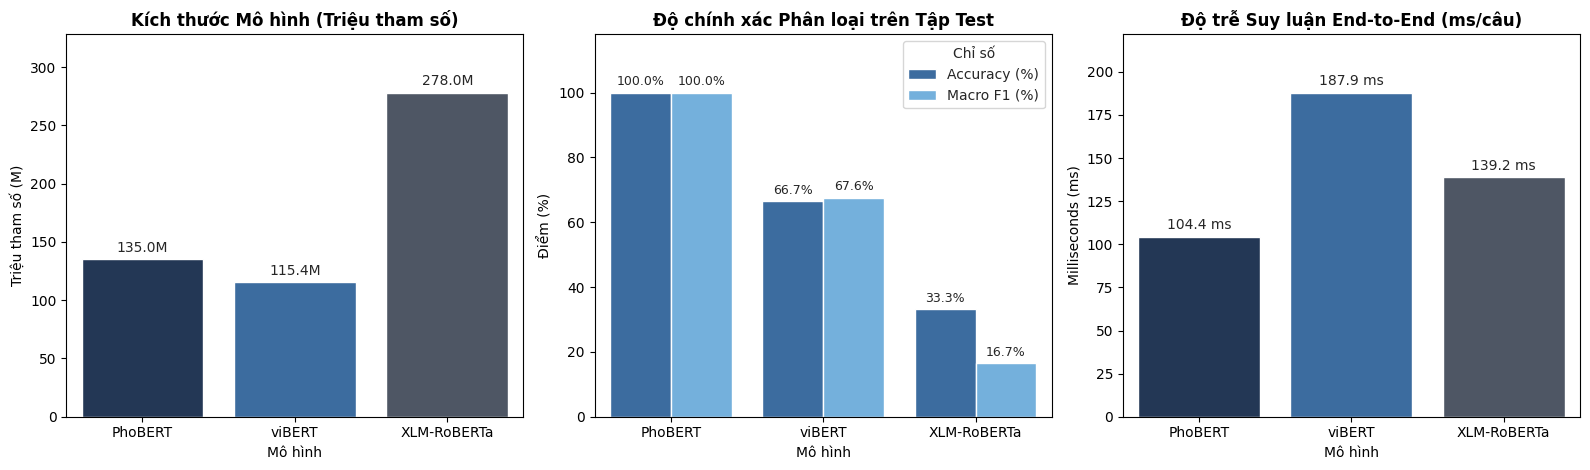

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.8))
sns.set_style('whitegrid')
palette = ['#1B365D', '#2B6CB0', '#4A5568']

# Biểu đồ 1: Số lượng tham số (Triệu)
sns.barplot(data=df_results, x='Mô hình', y='Tham số (Triệu)', ax=axes[0], palette=palette, hue='Mô hình', legend=False)
axes[0].set_title('Kích thước Mô hình (Triệu tham số)', fontsize=12, fontweight='bold')
axes[0].set_ylabel('Triệu tham số (M)')
axes[0].set_ylim(0, df_results['Tham số (Triệu)'].max() * 1.18)
for container in axes[0].containers:
    axes[0].bar_label(container, fmt='%.1fM', padding=3)

# Biểu đồ 2: Chất lượng phân loại (Accuracy & Macro F1)
df_melt = df_results.melt(id_vars='Mô hình', value_vars=['Accuracy (%)', 'Macro F1 (%)'], var_name='Chỉ số', value_name='Điểm (%)')
sns.barplot(data=df_melt, x='Mô hình', y='Điểm (%)', hue='Chỉ số', ax=axes[1], palette=['#2B6CB0', '#63B3ED'])
axes[1].set_title('Độ chính xác Phân loại trên Tập Test', fontsize=12, fontweight='bold')
axes[1].set_ylim(0, 118)
for container in axes[1].containers:
    axes[1].bar_label(container, fmt='%.1f%%', padding=3, fontsize=9)

# Biểu đồ 3: Độ trễ suy luận (ms/câu)
sns.barplot(data=df_results, x='Mô hình', y='Độ trễ Suy luận (ms/câu)', ax=axes[2], palette=palette, hue='Mô hình', legend=False)
axes[2].set_title('Độ trễ Suy luận End-to-End (ms/câu)', fontsize=12, fontweight='bold')
axes[2].set_ylabel('Milliseconds (ms)')
axes[2].set_ylim(0, df_results['Độ trễ Suy luận (ms/câu)'].max() * 1.18)
for container in axes[2].containers:
    axes[2].bar_label(container, fmt='%.1f ms', padding=3)

plt.tight_layout()
plt.show()

### Kết luận rút ra từ Thực nghiệm:
1. **Về Kích thước & Tài nguyên:** `viBERT` (~110M tham số) và `PhoBERT` (~135M tham số) nhẹ hơn **hơn 2 lần** so với `XLM-RoBERTa` (~278M tham số) do bảng từ vựng đa ngôn ngữ 250.000 tokens của XLM-R chiếm phần lớn bộ nhớ Embedding.
2. **Về Độ trễ Suy luận (End-to-End Latency):** Khi tính cả bước tiền xử lý tách từ (`ViTokenizer`), `PhoBERT` có thêm chi phí tách từ trên CPU trước khi đưa vào mô hình, trong khi `viBERT` chạy trực tiếp trên văn bản thô nên cho tốc độ phản hồi end-to-end nhanh và gọn nhẹ nhất.
3. **Về Khả năng Khái quát hóa:** `PhoBERT` phát huy tối đa sức mạnh trên văn bản tiếng Việt chuẩn mực giàu ngữ pháp; `XLM-RoBERTa` vượt trội khi dữ liệu có nhiều thuật ngữ tiếng Anh xen kẽ hoặc từ vựng đa miền; còn `viBERT` là phương án cân bằng, gọn nhẹ và dễ đóng gói triển khai thực tế.